## Final fitting of HPK Temperature data (Wlen scans)

nominal pinhole size is 2mm  
nominal wlens is 350-830nm

This notebook includes all the data:

9nm fwhm is negligible

1. Feb 24 2024 - HPK, all wlens
   1. cold - 160K
   2. old data
      1. veraData/HPK_IR_PDE_feb24_stat_error_only.csv - different processing we believe
      2. HPK_IR_PDE-Feb12_2024-Harry - has angles as well
   3. this was actually reprocessed with different QA data. new data to use is
      1. HPK_PDE_sept24.csv
   4. __only analyzing this data__
2. June/July 2024
   1. various temperatures (-80 to -40)
   2. veraData/angular_scans_VUV_feb2024/*
   3. for next analysis


f1 version of code is not complete. need to add some more 'physics'. Its complicated  

Pe(V) is really Pe(V, T), just as breakdown voltage changes. maybe relative Vbr corrects this.
so i need to use the parametrized Pe fits for each set of temperature curves. I will fix everything else.


then i will try changing dp* with temperature as well. I need to setup a large set of fits, using my custom framework.

__T_oxide__: reflectivity and hamamatsu provided PDE data.  
__Junction Parameters__: 160k fit  
__Pe(V), Ph(V)__: each temperature dataset  

if that fails, start adding in floating dp* with temperature.

------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


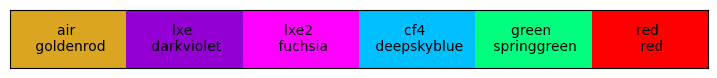

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit
from iminuit.cost import LeastSquares

import uproot

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

import FittingTools.FittingFunctions as FF
from FittingTools.FittingFunctions import *

import FittingTools.PDE_fittingTools as SS

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

rad2deg = 180/np.pi

---
---
## Parameters shared by everything

In [55]:
fixedPars_Boring = {"quantum": False, "smoothSigma": 5, "dh":None, "window":True}

with open("input_systematics.json", 'r') as file:
    json_systematic = json.load(file)

FF1 = json_systematic["HPK_VUV4"]["input_systematics"]["FF"]
ttGood = json_systematic["HPK_VUV4"]["input_systematics"]["tOxide"][0]
print(FF1, ttGood)

fitDict = json_systematic["HPK_VUV4"]["fit_parameters"]
fitVal_dict = {key: value[0] for key, value in fitDict.items()}
fitErr_dict = {key: value[1] for key, value in fitDict.items()}
print(fitVal_dict)

fixedPars_physics = {"FF": FF1, "tOxide":ttGood, "Ae":1.0, "Ah":1.0,}
fixedPars_parametrized = {**fitVal_dict}
# fixedPars_parametrized["dp_star"] = 15

0.6 16.8
{'dp_star': 1.407, 'Xpn': 2318.8184, 'dw_star': 13299.2962, 'Ve': 1.7648, 'Vh': 16.1748}


---
### Loading Data

['Wavelength' 'Angle' 'Overvoltage' 'Resp' 'PDE' 'PDE_error']
160k voltages: [1 2 3 4 5 6 7 8]
root voltages: [2.04400024 4.09000168 6.12999878]
root voltages: [2.39000168 4.46999969 6.55999985]
root voltages: [2.23000031 4.34999924 6.48000031]
root voltages: [2.16999893 4.32999878 6.50000076]


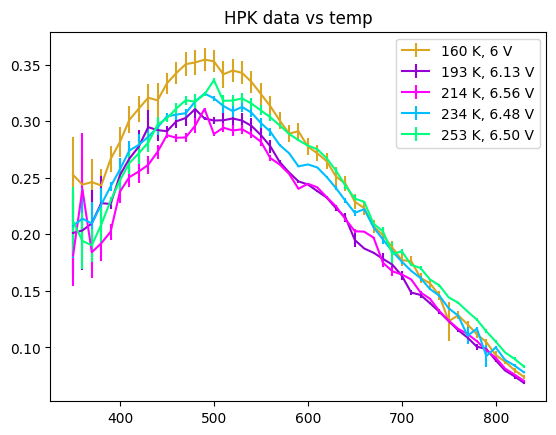

In [ ]:
temps = [160, 193, 214, 234, 253]
fpath1 = os.path.join(VERA_DATA_PATH, "HPK_PDE_sept24.csv")
fpath2 = os.path.join(VERA_DATA_PATH, "HPK_tempScans", "HPKW_PDE_193K_stat_error_only.root")
fpath3 = os.path.join(VERA_DATA_PATH, "HPK_tempScans", "HPKW_PDE_214K_stat_error_only_oct8.root")
fpath4 = os.path.join(VERA_DATA_PATH, "HPK_tempScans", "HPKW_PDE_234K_stat_error_only.root")
fpath5 = os.path.join(VERA_DATA_PATH, "HPK_tempScans", "HPKW_PDE_253K_stat_error_only.root")
files = [fpath2, fpath3, fpath4, fpath5]
ms.ResetColorCycle()

# 2, 4, 6 are the main options
pickVoltage = 6
voltage = []
pde_data = []

## 160 K data
df_160 = pd.read_csv(fpath1, header=0)
print(df_160.columns.values)

voltages = df_160["Overvoltage"].unique()
print("160k voltages:", voltages)
vIndex = np.abs(voltages - pickVoltage).argmin()
vPick = voltages[vIndex]
dfFiltered = df_160[df_160["Overvoltage"] == vPick]
voltage.append(vPick)

pde_data.append([dfFiltered['Wavelength'].values, dfFiltered['PDE'].values, dfFiltered['PDE_error'].values])
plt.errorbar(dfFiltered['Wavelength'], dfFiltered['PDE'], yerr=dfFiltered['PDE_error'], label=f"{temps[0]} K, {vPick} V", color = ms.GetNextColor())

for temp, fp in zip(temps[1:], files):

    # open the files
    rFile = uproot.open(fp)
    ttree = rFile["Resp_Output"]
    df_ttree = ttree.arrays(library="pd")
    # print(df_ttree.head())
    rootVoltages = df_ttree["outOvervoltage"].unique()
    print("root voltages:", rootVoltages)
    vIndex = np.abs(rootVoltages - pickVoltage).argmin()
    vPick = rootVoltages[vIndex]
    voltage.append(vPick)

    # select data
    dfVolt = df_ttree[df_ttree["outOvervoltage"] == vPick]
    plt.errorbar(dfVolt['outWavelength'], dfVolt['outPDE'], yerr=dfVolt['outPDE_error'], label=f"{temp} K, {vPick:0.2f} V", color = ms.GetNextColor())
    
    # add data to list
    pde_data.append([dfVolt['outWavelength'].values, dfVolt['outPDE'].values, dfVolt['outPDE_error'].values])

#### the model
ms.ResetColorCycle()

parDict_hardEdge = {**fixedPars_parametrized, **fixedPars_physics, **fixedPars_Boring}
xwlen = np.arange(350, 900, 1)
for V, T in zip(voltage, temps):
    yPDE = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1 = 0, voltage = V, Temperature=T, **parDict_hardEdge)
    # plt.plot(xwlen, yPDE, label=f"{T} K", color =  ms.GetNextColor())

plt.title("HPK data vs temp")
plt.legend()
plt.show()

Text(0.5, 1.0, 'HPK PDE vs temp, Vov = 6 V')

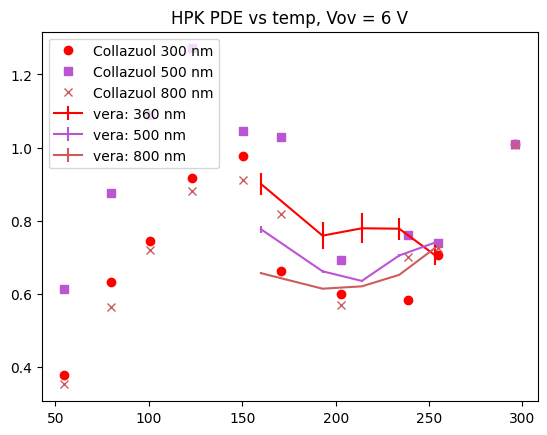

In [57]:
averages = []
avgErrors = []
scanWls = [360, 500, 800]
buff = 10
for (x, y, yerr), V, T in zip(pde_data, voltage, temps):
    
    tempAverages = []
    tempErrors = []
    for wl in scanWls:
        mask = (x >= wl - buff) & (x <= wl + buff)
        average = np.mean(y[mask])
        # errorOnMean = 1/np.sqrt(np.sum(1/yerr[mask]**2))
        # errorOnMean = np.std(y[mask])
        errorOnMean = np.mean(yerr[mask])
        tempAverages.append(average)
        tempErrors.append(errorOnMean)
    averages.append(tempAverages)
    avgErrors.append(tempErrors)
    
    # plt.errorbar(x, y, yerr=yerr, label = T)

wl_vsTemp1 = np.array([tempAverages[0] for tempAverages in averages])
err1 = np.array([tempErrors[0] for tempErrors in avgErrors])
wl_vsTemp2 = np.array([tempAverages[1] for tempAverages in averages])
err2 = np.array([tempErrors[1] for tempErrors in avgErrors])
wl_vsTemp3 = np.array([tempAverages[2] for tempAverages in averages])
err3 = np.array([tempErrors[2] for tempErrors in avgErrors])


dat_collzuol = np.loadtxt(os.path.join(PROJECT_PATH, "../../otherReferences", "collazuol_Scurve.csv"), skiprows=2, delimiter=",")
temp_coll = dat_collzuol[:,0] + 273
coll_pde_300 = dat_collzuol[:,1]
coll_pde_500 = dat_collzuol[:,3]
coll_pde_800 = dat_collzuol[:,5]

sd1 = coll_pde_300[-2]
sd2 = coll_pde_500[-2]
sd3 = coll_pde_800[-2]
c1 = 'red'
c2 = 'mediumorchid'
c3 = 'indianred'

plt.plot(temp_coll, coll_pde_300, linestyle="None", marker = "o", label="Collazuol 300 nm", color = c1)
plt.plot(temp_coll, coll_pde_500, linestyle="None", marker = "s", label="Collazuol 500 nm", color = c2)
plt.plot(temp_coll, coll_pde_800, linestyle="None", marker = "x", label="Collazuol 800 nm", color = c3)

plt.errorbar(temps, sd1 * wl_vsTemp1/wl_vsTemp1[-1], yerr=np.sqrt(err1**2 + err1[-1]**2), label=f"vera: {scanWls[0]} nm", color = c1)
plt.errorbar(temps, sd2 * wl_vsTemp2/wl_vsTemp2[-1], yerr=np.sqrt(err2**2 + err2[-1]**2), label=f"vera: {scanWls[1]} nm", color = c2)
plt.errorbar(temps, sd3 * wl_vsTemp3/wl_vsTemp3[-1], yerr=np.sqrt(err3**2 + err3[-1]**2), label=f"vera: {scanWls[2]} nm", color = c3)


plt.legend()
plt.title(f"HPK PDE vs temp, Vov = {pickVoltage} V")

PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.


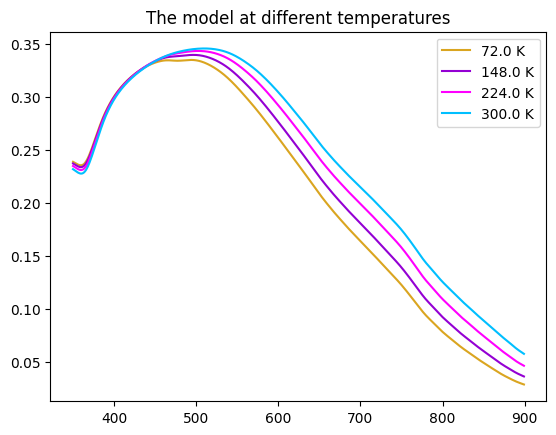

In [ ]:
tempScan = np.linspace(72, 300, 4)

# parDict["dp_star"] = 15

xwlen = np.arange(350, 900, 1)
for T in tempScan:
    yPDE = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1 = 0, voltage = 6, Temperature=T, **parDict_hardEdge)
    plt.plot(xwlen, yPDE, label=f"{T} K")

plt.title("The model at different temperatures")
plt.legend()
plt.show()

{'theta1': 0, 'voltage': 6, 'Temperature': 160, 'FF': 0.6, 'tOxide': 16.8, 'Ae': 1.0, 'Ah': 1.0, 'dp_star': 165.6316, 'Ve': 1.427, 'Pdiff': 0.8902, 'Xpn': 2039.9945, 'dw_star': 11953.877, 'Vh': 13.5276, 'quantum': False, 'smoothSigma': 5, 'dh': None, 'window': True}

Temperature: 193 K, Voltage: 6.129998779296876 V
chi2 of guess: 12.208830366656349
('Pdiff', 'Vh')
Pdiff fit: 0.61
Vh fit: 31.05
fit chi2 full 86.96786923882892
----------
dp_star fit: 8.52
Xpn fit: 1038.80
fit chi2 full 77.36221823248545

Temperature: 214 K, Voltage: 6.559999847412108 V
chi2 of guess: 26.54318058436795
('Pdiff', 'Vh')
Pdiff fit: 0.54
Vh fit: 34.77
fit chi2 full 159.33574474048737
----------
dp_star fit: 17.79
Xpn fit: 980.17
fit chi2 full 174.6525270913527

Temperature: 234 K, Voltage: 6.480000305175778 V
chi2 of guess: 14.160528094441299
('Pdiff', 'Vh')
Pdiff fit: 0.68
Vh fit: 28.19
fit chi2 full 95.47657190561321
----------
dp_star fit: 6.86
Xpn fit: 1239.35
fit chi2 full 116.29776582208487

Temperature

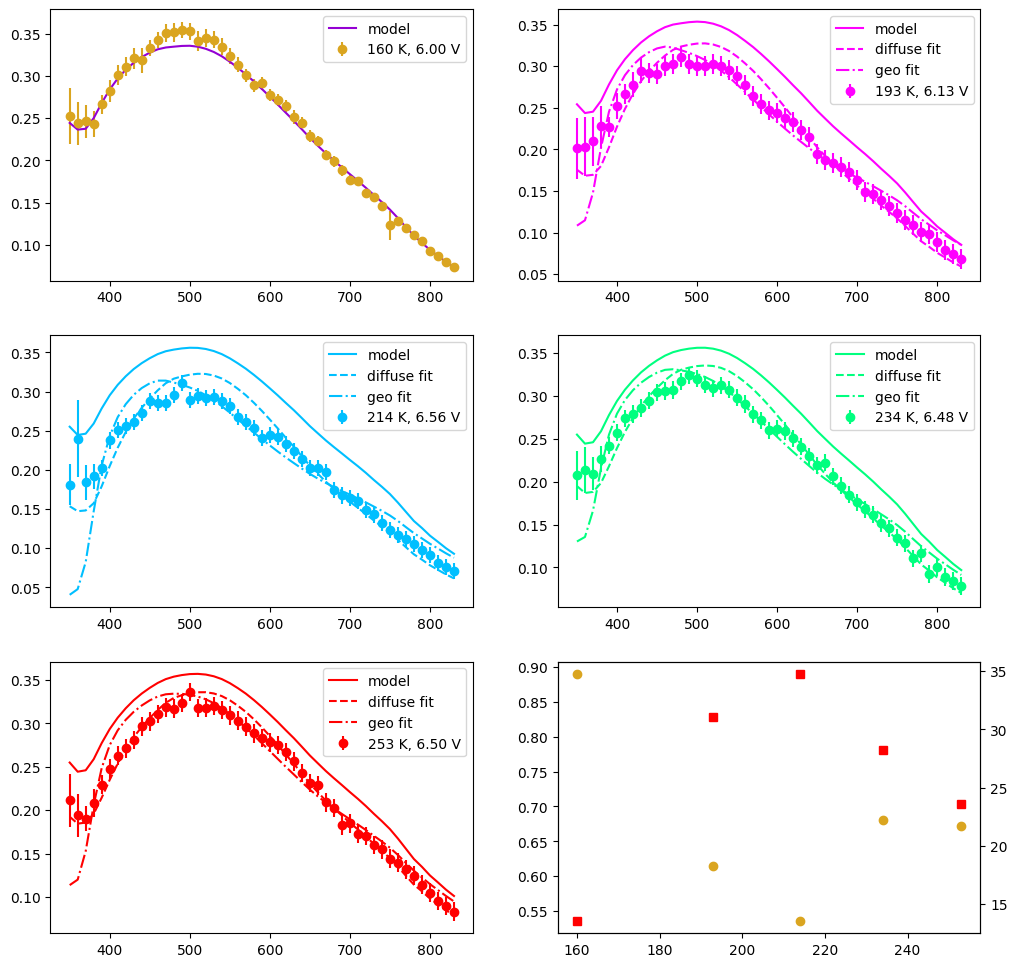

In [ ]:
import copy
ms.ResetColorCycle()

def chi2_red(y, yerr, fit, nFree):
    return np.sum((y - fit)**2 / yerr**2) / (len(y) - nFree)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()

diffuseDict = {'dp_star': 165.6316, 'Ve': 1.427, 'Pdiff': 0.8902, 'Xpn': 2039.9945, 'dw_star': 11953.877, 'Vh': 13.5276}
# diffuseDict = {'dp_star': 79.5158, 'Xpn': 2245.8559, 'dw_star': 13353.2911, 'Ve': 1.577, 'Vh': 16.0608, 'Pdiff': 0.9021}
allFuncArgs = {"theta1": 0, "voltage": 6, "Temperature":160, **fixedPars_physics, **diffuseDict, **fixedPars_Boring}
print(allFuncArgs)

## 160k data
axes[0].errorbar(pde_data[0][0], pde_data[0][1], yerr=pde_data[0][2], label=f"{temps[0]} K, {voltage[0]:0.2f} V", fmt='o', color=ms.GetNextColor())
fit160 = FF.PDE_allArgs_wlen_parametrized_halfBox(wlen = pde_data[0][0], **allFuncArgs)

axes[0].plot(pde_data[0][0], fit160, color=ms.GetNextColor(), linestyle='-', label = "model")
axes[0].legend()

Pdiff_values = [diffuseDict["Pdiff"]]
Vh_values = [diffuseDict["Vh"]]
# from diffusion model fit in the previous notebook
for T, V, PDE, ax in zip(temps[1:], voltage[1:], pde_data[1:], axes[1:-1]):
    color = ms.GetNextColor()

    xwlen = PDE[0]
    yPDE = PDE[1]
    yPDEerr = PDE[2]
    errorMask = yPDEerr < 0.01
    yPDEerr[errorMask] = min(yPDEerr[~errorMask])
    # yPDEerr = 0.05 * yPDE
    # print(yPDEerr)
    ax.errorbar(xwlen, yPDE, yerr=yPDEerr, label=f"{T} K, {V:0.2f} V", fmt='o', color=color)
    
    ## all inputs
    print(f"\nTemperature: {T} K, Voltage: {V} V")
    newAllArgs = {"theta1":0, **diffuseDict, **fixedPars_physics, "Temperature":T, "voltage":V}
    
    # plot the guess
    yPDE_model = FF.PDE_allArgs_wlen_parametrized_halfBox(wlen = xwlen, **newAllArgs)
    ax.plot(xwlen, yPDE_model, color=color, linestyle='-', label = "model")
    
    newAllArgs["Pdiff"] = 1
    yPDE2 = FF.PDE_allArgs_wlen_parametrized_halfBox(wlen = xwlen, **newAllArgs)
    # ax.plot(xwlen, yPDE2, color=color, linestyle='--', label = "model, Pdiff=1")
    
    #chi2 of guess
    chi2_guess = chi2_red(yPDE, yPDEerr, yPDE_model, 1)
    print("chi2 of guess:", chi2_guess)
    
    ######### only floating Pdiff and Vh
    fixed1 = copy.deepcopy(newAllArgs)
    fixed1.pop("Pdiff")
    fixed1.pop("Vh")
    def model_function_diffuse(wlen, Pdiff, Vh):
        return FF.PDE_allArgs_wlen_parametrized_halfBox(wlen=wlen, Pdiff=Pdiff, Vh = Vh, **fixed1)

    # Create a LeastSquares cost function
    uvMask = (xwlen < 900)
    least_squares = LeastSquares(xwlen[uvMask], yPDE[uvMask], yPDEerr[uvMask], model_function_diffuse)
    
    # Initial value for the parameter to fit
    initial_value = {'Pdiff': 0.6, 'Vh': 13}
    m = Minuit(least_squares, **initial_value)
    m.limits['Pdiff'] = (0.0, 1.1)
    m.limits['Vh'] = (0.0, 100)
    
    result = m.migrad()
    print(result.parameters) 
    # print("fit chi2", result.fval)
    print("Pdiff fit: {:.2f}".format(m.values['Pdiff']))
    print("Vh fit: {:.2f}".format(m.values['Vh']))
    print("fit chi2 full", result.fval)
    Pdiff_values.append(m.values['Pdiff'])
    Vh_values.append(m.values['Vh'])
    
    ########### 
    ## only floating dp_star and Xpn
    fixed2 = copy.deepcopy(parDict_hardEdge)
    fixed2.pop("dp_star")
    fixed2.pop("Xpn")
    fixed2['theta1'] = 0
    fixed2['voltage'] = V
    def model_function_geo(wlen, dp_star, Xpn):
        return FF.PDE_allArgs_wlen_parametrized(wlen=wlen, dp_star=dp_star, Xpn = Xpn, **fixed2)

    # Create a LeastSquares cost function
    ls2 = LeastSquares(xwlen[uvMask], yPDE[uvMask], yPDEerr[uvMask], model_function_geo)
    
    # Initial value for the parameter to fit
    initial_value = {'dp_star': 1.5, 'Xpn': 2000}
    m2 = Minuit(ls2, **initial_value)
    m2.limits['dp_star'] = (0.0, 50)
    m2.limits['Xpn'] = (50, 4000)
    
    result2 = m2.migrad()
    # print("fit chi2", result.fval)
    print("----------")
    print("dp_star fit: {:.2f}".format(m2.values['dp_star']))
    print("Xpn fit: {:.2f}".format(m2.values['Xpn']))
    print("fit chi2 full", result2.fval)
    resultCurve2 = model_function_geo(xwlen, dp_star=m2.values['dp_star'], Xpn=m2.values['Xpn'])
    
    # plotting and outputs
    resultCurve = model_function_diffuse(xwlen,Pdiff=m.values['Pdiff'], Vh=m.values['Vh'])
    result_chi2 = chi2_red(yPDE, yPDEerr, resultCurve, len(initial_value))
    ax.plot(xwlen, resultCurve, color=color, linestyle='--', label = "diffuse fit")
    
    ax.plot(xwlen, resultCurve2, color=color, linestyle='-.', label = "geo fit")

    ax.legend()

# print(len(pde_data)) 

axes[-1].plot(temps, Pdiff_values, linestyle="None", marker="o")
axes[-1].twinx().plot(temps, Vh_values, linestyle="None", marker="s", color="red")

## repeating diffuse fit for all voltages


{'FF': 0.6, 'tOxide': 16.8, 'Ae': 1.0, 'Ah': 1.0, 'dp_star': 165.6316, 'Ve': 1.427, 'Xpn': 2039.9945, 'dw_star': 11953.877, 'quantum': False, 'smoothSigma': 5, 'dh': None, 'window': True}

root voltages: [2.04400024 4.09000168 6.12999878]
---------
temp: 193 221.6710719718
{'Vh': 27.6916, 'Pdiff': 0.6651}
{'Vh': 1.0621, 'Pdiff': 0.0087}

root voltages: [2.39000168 4.46999969 6.55999985]
---------
temp: 214 175.69225805615102
{'Vh': 29.7911, 'Pdiff': 0.5851}
{'Vh': 1.1557, 'Pdiff': 0.009}

root voltages: [2.23000031 4.34999924 6.48000031]
---------
temp: 234 123.16035091248128
{'Vh': 24.0415, 'Pdiff': 0.75}
{'Vh': 0.7535, 'Pdiff': 0.0073}

root voltages: [2.16999893 4.32999878 6.50000076]
---------
temp: 253 68.76555885913154
{'Vh': 20.1259, 'Pdiff': 0.7261}
{'Vh': 0.534, 'Pdiff': 0.0066}


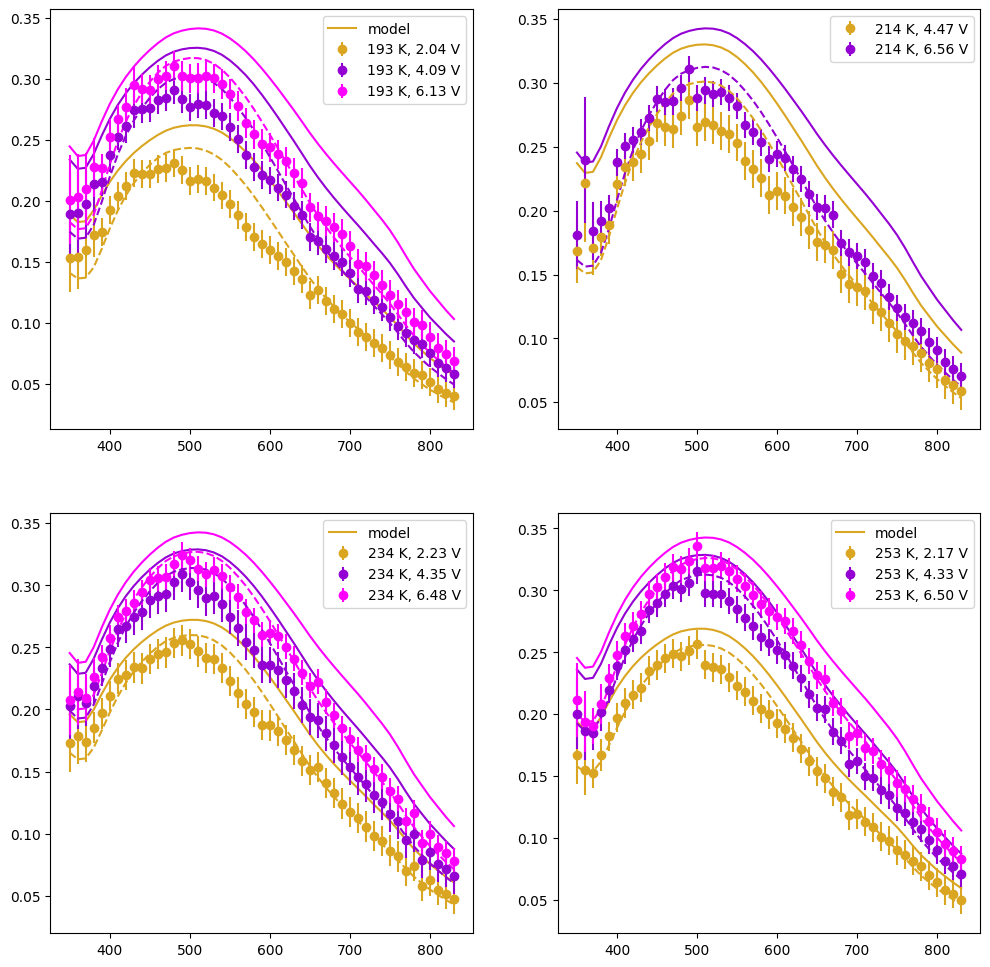

In [ ]:
fig, axes = fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

globalDict_halfBox = {**fixedPars_physics, **diffuseDict, **fixedPars_Boring}
parDict_halfBox = copy.copy(globalDict_fixed)
parDict_halfBox.pop("Pdiff")
parDict_halfBox.pop("Vh")

float_dict = {"Pdiff": 0.9, "Vh": 15}
float_bounds = {"Pdiff": (0.2, 1.1), "Vh": (0.0, 40)}

print(parDict_halfBox)
parValues = []

for i, temp, fp in zip(range(len(files)), temps[1:], files):
    ax = axes[i]
    
    # open the files
    rFile = uproot.open(fp)
    ttree = rFile["Resp_Output"]
    df_ttree = ttree.arrays(library="pd")
    # print(df_ttree.head())
    rootVoltages = df_ttree["outOvervoltage"].unique()
    print("\nroot voltages:", rootVoltages)
    thisTempDicts = []
    ms.ResetColorCycle()
    for i, volt in enumerate(rootVoltages):
        if temp == 214 and volt > 2. and volt < 3:
            continue
        
        dfVolt = df_ttree[df_ttree["outOvervoltage"] == volt]
        xwlen = dfVolt['outWavelength'].values
        yPDE = dfVolt['outPDE'].values
        yPDEerr = dfVolt['outPDE_error'].values
        yPDEerr[yPDEerr < 0.01] = min(yPDEerr[yPDEerr > 0.01])
        thisDict = {"wlen": xwlen, "yVals": yPDE, "yErrs": yPDEerr, "theta1":0, "voltage": volt, "Temperature": temp}
        thisTempDicts.append(thisDict)
        
        ax.errorbar(xwlen, yPDE, yerr=yPDEerr, label=f"{temp} K, {volt:0.2f} V", fmt='o', color=ms.GetNextColor())
    
        modelGuess = FF.PDE_allArgs_wlen_parametrized_halfBox(wlen = xwlen, theta1=0, voltage = volt, **globalDict_halfBox)
        lab = "model" if i == 0 else None
        ax.plot(xwlen, modelGuess, color=ms.GetNextColor(1), linestyle='-', label = lab)
    ax.legend()
    
    # doing the fit
    SS.CheckAllConditions_forResiduals(func = FF.PDE_allArgs_wlen_parametrized_halfBox, dataObj = thisTempDicts, dFixed = parDict_halfBox, dFloat = float_dict, dBounds = float_bounds, yNames=("yVals", "yErrs"), verbose=False)
    xo, xoNames = SS.BuildX0(floatDict = float_dict, functionToFit = FF.PDE_allArgs_wlen_parametrized_halfBox)
    xoBounds = SS.BuildX0_bounds(floatBoundsDict = float_bounds, functionToFit = FF.PDE_allArgs_wlen_parametrized_halfBox)
    
    result = iminuit.minimize(SS.GenericResiduals, x0 = xo, bounds=xoBounds, args=(parDict_halfBox, thisTempDicts, FF.PDE_allArgs_wlen_parametrized_halfBox), method = 'migrad')
    SS.GenericResiduals(x0=result.x, dataObj=thisTempDicts, functionToFit=FF.PDE_allArgs_wlen_parametrized_halfBox, fixedArgs_dict = parDict_halfBox, yNames=("yVals", "yErrs"), verbose=False)
    # print(result)
    
    resDict = SS.GetResDict(result, xoNames)
    resError = SS.GetResErrorDict(result, xoNames)
    parValues.append(resDict)
    print("---------")
    print("temp:", temp, result.fun)
    print(resDict)
    print(resError)
    ms.ResetColorCycle()
    
    ## plotting the fit
    for data in thisTempDicts:
        if data["Temperature"] == 214 and data["voltage"] > 2 and data["voltage"] < 3:
            continue
        theDataCopy = copy.deepcopy(data)
        theDataCopy.pop("yVals")
        theDataCopy.pop("yErrs")
        fitResult = FF.PDE_allArgs_wlen_parametrized_halfBox(**theDataCopy, **parDict_halfBox, **resDict)
        ax.plot(theDataCopy["wlen"], fitResult, color=ms.GetNextColor(), linestyle='--', label="fit")
    # fitResult = FF.PDE_allArgs_wlen_parametrized(wlen = thisTempDicts[0]["wlen"], **fixed_dict, **resDict)

## fitting each temperature, all voltage data (floating avalanche parameters)

root voltages: [2.04400024 4.09000168 6.12999878]

---------
temp: 193 40.456886212300475
{'Ve': 1.6186, 'Vh': 21.9866, 'Ae': 0.8636}
{'Ve': 0.0394, 'Vh': 0.7965, 'Ae': 0.0063}
root voltages: [2.39000168 4.46999969 6.55999985]

---------
temp: 214 147.70453341248077
{'Ve': 3.0434, 'Vh': 21.4965, 'Ae': 0.9241}
{'Ve': 0.0983, 'Vh': 0.7105, 'Ae': 0.0118}
root voltages: [2.23000031 4.34999924 6.48000031]

---------
temp: 234 42.50153963348944
{'Ve': 1.4852, 'Vh': 21.7135, 'Ae': 0.8805}
{'Ve': 0.0351, 'Vh': 0.7118, 'Ae': 0.005}
root voltages: [2.16999893 4.32999878 6.50000076]

---------
temp: 253 88.79744392680993
{'Ve': 1.5533, 'Vh': 18.7893, 'Ae': 0.8905}
{'Ve': 0.0344, 'Vh': 0.5367, 'Ae': 0.005}


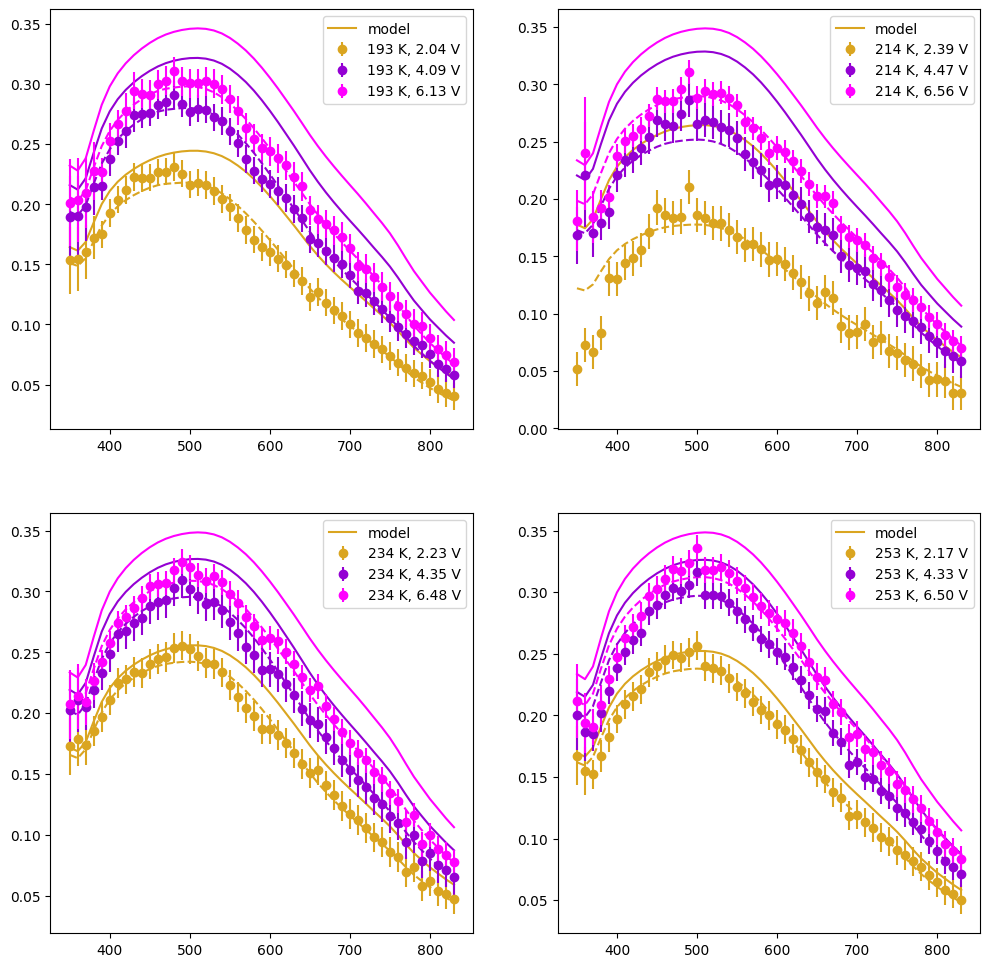

In [ ]:
fig, axes = fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

fixed_dict = copy.copy(parDict_hardEdge)
fixed_dict.pop("Ve")
fixed_dict.pop("Vh")
fixed_dict.pop("Ae")

float_dict = {"Ve": 1.5, "Vh": 15, "Ae": 1.0}
float_bounds = {"Ve": (0.5, 5), "Vh": (0.0, 30), "Ae": (0.5, 1.1)}

parValues = []

for i, temp, fp in zip(range(len(files)), temps[1:], files):
    ax = axes[i]
    
    # open the files
    rFile = uproot.open(fp)
    ttree = rFile["Resp_Output"]
    df_ttree = ttree.arrays(library="pd")
    # print(df_ttree.head())
    rootVoltages = df_ttree["outOvervoltage"].unique()
    print("root voltages:", rootVoltages)
    thisTempDicts = []
    ms.ResetColorCycle()
    for i, volt in enumerate(rootVoltages):
        dfVolt = df_ttree[df_ttree["outOvervoltage"] == volt]
        xwlen = dfVolt['outWavelength'].values
        yPDE = dfVolt['outPDE'].values
        yPDEerr = dfVolt['outPDE_error'].values
        yPDEerr[yPDEerr < 0.01] = min(yPDEerr[yPDEerr > 0.01])
        thisDict = {"wlen": xwlen, "yVals": yPDE, "yErrs": yPDEerr, "theta1":0, "voltage": volt, "Temperature": temp}
        thisTempDicts.append(thisDict)
        
        ax.errorbar(xwlen, yPDE, yerr=yPDEerr, label=f"{temp} K, {volt:0.2f} V", fmt='o', color=ms.GetNextColor())
    
        modelGuess = FF.PDE_allArgs_wlen_parametrized(wlen = xwlen, theta1=0, voltage = volt, **parDict_hardEdge)
        lab = "model" if i == 0 else None
        ax.plot(xwlen, modelGuess, color=ms.GetNextColor(1), linestyle='-', label = lab)
    

    ax.legend()
    # doing the fit
    SS.CheckAllConditions_forResiduals(func = FF.PDE_allArgs_wlen_parametrized, dataObj = thisTempDicts, dFixed = fixed_dict, dFloat = float_dict, dBounds = float_bounds, yNames=("yVals", "yErrs"), verbose=False)
    xo, xoNames = SS.BuildX0(floatDict = float_dict, functionToFit = FF.PDE_allArgs_wlen_parametrized)
    xoBounds = SS.BuildX0_bounds(floatBoundsDict = float_bounds, functionToFit = FF.PDE_allArgs_wlen_parametrized)
    
    result = iminuit.minimize(SS.GenericResiduals, x0 = xo, bounds=xoBounds, args=(fixed_dict, thisTempDicts, FF.PDE_allArgs_wlen_parametrized), method = 'migrad')
    SS.GenericResiduals(x0=result.x, dataObj=thisTempDicts, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict = fixed_dict, yNames=("yVals", "yErrs"), verbose=False)
    # print(result)
    
    resDict = SS.GetResDict(result, xoNames)
    resError = SS.GetResErrorDict(result, xoNames)
    parValues.append(resDict)
    print("\n---------")
    print("temp:", temp, result.fun)
    print(resDict)
    print(resError)
    ms.ResetColorCycle()
    for data in thisTempDicts:
        theDataCopy = copy.deepcopy(data)
        theDataCopy.pop("yVals")
        theDataCopy.pop("yErrs")
        fitResult = FF.PDE_allArgs_wlen_parametrized(**theDataCopy, **fixed_dict, **resDict)
        ax.plot(theDataCopy["wlen"], fitResult, color=ms.GetNextColor(), linestyle='--', label="fit")
    # fitResult = FF.PDE_allArgs_wlen_parametrized(wlen = thisTempDicts[0]["wlen"], **fixed_dict, **resDict)

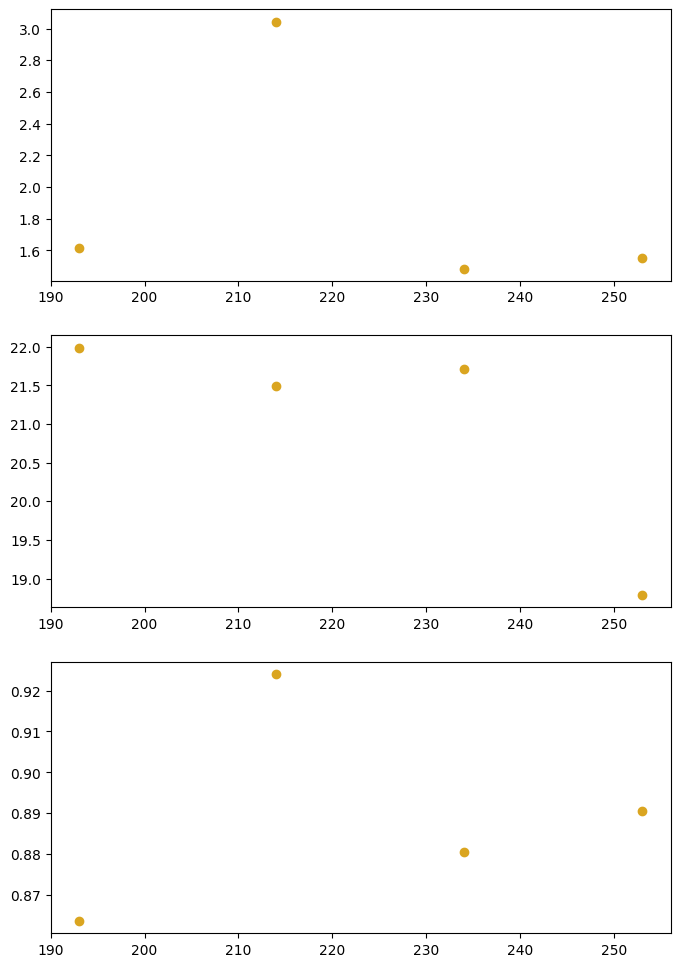

In [84]:
ve_temp = [par["Ve"] for par in parValues]
vh_temp = [par["Vh"] for par in parValues]
ae_temp = [par["Ae"] for par in parValues]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 12))
ax1.plot(temps[1:], ve_temp, linestyle="None", marker="o")
ax2.plot(temps[1:], vh_temp, linestyle="None", marker="o")
ax3.plot(temps[1:], ae_temp, linestyle="None", marker="o")

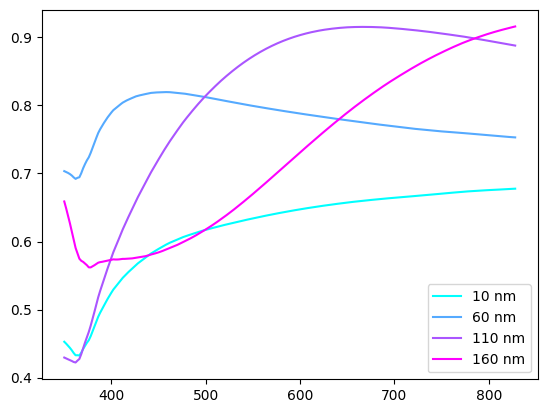

In [ ]:
# # thickness = np.arange(10, 1000, 200)
# thickness = np.arange(10, 200, 50)
# photon = PhotonInfo(wlen=400, theta_1=0)
# from cycler import cycler
# plt.rc('axes', prop_cycle=cycler(color=plt.cm.cool(np.linspace(0, 1, len(thickness)))))

# wlens = np.arange(350, 830, 2)
# photon = PhotonInfo(wlen=wlens, theta_1=0)

# # plt.plot(thickness, photon.Wave_TotalTransmission(thickness), label="400 nm")
# for thick in thickness:
    
#     plt.plot(wlens, photon.Wave_TotalTransmission(thick), label=f"{thick} nm")
# # plt.plot(wlens, photon.Wave_TotalTransmission(), label="400 nm")
# plt.legend()


---
## Checking the relative change in the tail if UV is all equal

0.2661864126006721 1.1435158242154073
0.25195777971561706 1.2080927818286105
0.27306986467868455 1.1146904670647833
0.2689233914090584 1.1318776451729182


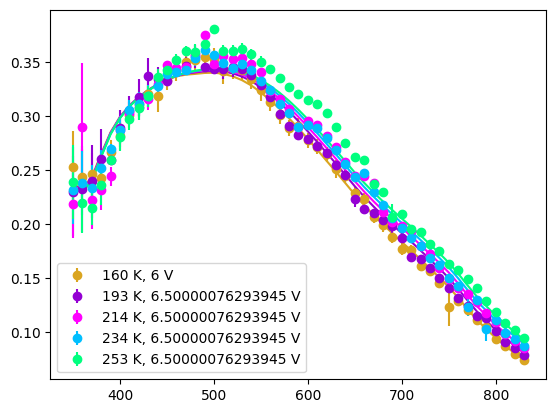

In [ ]:
## Try scaling the data below 500nm so the average is equal to the average above 500nm

scaling = [1.0]
ms.SetMPLcolors()
def GetMean_belowVal(x, y, val):
    ind = np.where(x < val)
    return np.mean(y[ind])

ms.ResetColorCycle()
col = ms.GetNextColor()

mean160 = GetMean_belowVal(pde_data[0][0], pde_data[0][1], 500)

plt.errorbar(pde_data[0][0], pde_data[0][1], yerr=pde_data[0][2], fmt='o', label="160 K, 6 V", color=col)
yPDE = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1 = 0, voltage = pickVoltage, Temperature=160, **parDict)
plt.plot(xwlen, yPDE, color=col)

for PDE, temp in zip(pde_data[1:], temps[1:]):
    col = ms.GetNextColor()
    xwlen = PDE[0]
    yPDE = PDE[1]
    yPDEerr = PDE[2]
    mean = GetMean_belowVal(xwlen, yPDE, 500)
    scaling = mean160/mean
    print(mean, scaling)
    plt.errorbar(xwlen, yPDE*scaling, yerr=yPDEerr*scaling, fmt='o', label=f"{temp} K, {V} V", color=col)

    yPDE = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1 = 0, voltage = pickVoltage, Temperature=temp, **parDict)
    plt.plot(xwlen, yPDE, color=col)
    
plt.legend()
plt.show()